# Многовыходная регрессия

Обучим общую MLP предсказывать Weight, Waist и Pulse на Linnerud. Сравним ошибки трёх выходов и проверим, как влияет увеличение веса ошибки Weight.


## Ход работы

Загружаем 20 наблюдений Linnerud с тремя признаками и тремя целями. Делим данные на train, validation и test, затем отдельно масштабируем признаки и целевые величины по обучающей части. Создаём общую MLP с тремя выходами и обучаем её с контролем validation.

Возвращаем веса лучшей эпохи, переводим предсказания в исходные единицы и считаем MSE для Weight, Waist и Pulse отдельно. Дополнительно сравниваем веса целей `[1, 1, 1]` и `[2, 1, 1]` при одинаковых остальных настройках. По ошибкам отдельных выходов проверяем, как изменение функции потерь повлияло на баланс качества.


### Подключаем библиотеки для регрессии

Используем `load_linnerud`, нормализацию, PyTorch и Matplotlib. Здесь один объект имеет три входных признака, а модель одновременно предсказывает Weight, Waist и Pulse.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

torch.manual_seed(42)
np.random.seed(42)


### Загружаем двадцать наблюдений

Проверяем формы `X` и `y`: обе матрицы имеют размер `(20, 3)`. Малое количество объектов означает, что любые оценки на четырёх проверочных точках будут нестабильными.

In [2]:

# 1. Готовый датасет
data = load_linnerud()

X = data.data.astype(np.float32)
y = data.target.astype(np.float32)

print("X:", X.shape)
print("y:", y.shape)


X: (20, 3)
y: (20, 3)


### Откладываем validation и test

Разделяем наблюдения на train/validation/test до любой подгонки нормализаторов. Валидация нужна для выбора эпохи, а тест — для последней проверки качества.

In [3]:

# 2. Разделение данных
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)


### Масштабируем признаки и цели

Обучаем два `StandardScaler` только на train. Масштабирование целей особенно важно: Weight, Waist и Pulse измерены в разных единицах, поэтому их исходные квадратичные ошибки несопоставимы напрямую.

In [4]:

# 3. Нормализация по обучающим данным
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train)
y_val = scaler_y.transform(y_val)
y_test = scaler_y.transform(y_test)


### Преобразуем массивы в тензоры

PyTorch ожидает `float32`. Сохраняем одинаковый порядок трёх выходов, чтобы позже вернуть прогнозы в исходные единицы и корректно подписать MSE.

In [5]:

# 4. Преобразование в тензоры
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)


### Создаём MLP с тремя выходами

Общие скрытые слои одновременно ищут представления для Weight, Waist и Pulse. Последний `nn.Linear(..., 3)` выдаёт три числа на каждый объект.

In [6]:

# 5. Многовыходная MLP
model = nn.Sequential(
    nn.Linear(3, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

patience = 30
loss_fn = nn.MSELoss()

train_history = []
val_history = []

best_val_loss = float("inf")
best_epoch = 0


### Настраиваем контроль лучшей эпохи

Сохраняем место для лучших весов и счётчик эпох без улучшения. `patience` регулирует время ожидания; он не гарантирует, что выбранная эпоха будет лучшей на неизвестном тесте.

In [7]:
best_weights = copy.deepcopy(model.state_dict())

patience = 100
epochs_without_improvement = 0


### Обучаем общую сеть

Квадратичные ошибки трёх целей усредняются или взвешиваются согласно текущим настройкам. Сравнение Train Loss и Validation Loss помогает замечать переобучение на 12 обучающих объектах.

In [8]:

# 6. Обучение
train_mse_history = []
val_mse_history = []

# Веса ошибок трёх выходов
weights = torch.tensor([1.0, 1.0, 1.0])

for epoch in range(1000):
    model.train()

    optimizer.zero_grad()

    predictions = model(X_train)

    # Квадраты ошибок каждого выхода
    errors = (predictions - y_train) ** 2

    # Взвешенная ошибка
    train_loss = (errors * weights).mean()

    train_loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)

        val_errors = (val_predictions - y_val) ** 2
        val_loss = (val_errors * weights).mean()

    with torch.no_grad():
        train_mse = ((model(X_train) - y_train) ** 2).mean(dim=0)
        val_mse = ((model(X_val) - y_val) ** 2).mean(dim=0)

        train_mse_history.append(train_mse.cpu().numpy().copy())
        val_mse_history.append(val_mse.cpu().numpy().copy())

    train_history.append(train_loss.item())
    val_history.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train: {train_loss.item():.5f} | "
            f"Val: {val_loss.item():.5f}"
        )

    if epochs_without_improvement >= patience:
        print("Early Stopping!")
        break


Epoch  20 | Train: 0.96110 | Val: 1.22905
Epoch  40 | Train: 0.90273 | Val: 1.15507
Epoch  60 | Train: 0.85013 | Val: 1.10962
Epoch  80 | Train: 0.81111 | Val: 1.10492
Epoch 100 | Train: 0.77727 | Val: 1.11352
Epoch 120 | Train: 0.74310 | Val: 1.11846
Epoch 140 | Train: 0.70554 | Val: 1.12616
Epoch 160 | Train: 0.66243 | Val: 1.13710
Early Stopping!


### Возвращаем сохранённые веса

После остановки восстанавливаем наиболее удачное состояние по validation. Отдельно выводим номер лучшей эпохи, чтобы не путать его с последней обработанной эпохой.

In [9]:

# 7. Восстановление лучших весов
model.load_state_dict(best_weights)
model.eval()

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation MSE:", best_val_loss)



Лучшая эпоха: 79
Лучший Validation MSE: 1.1048791408538818


### Оцениваем три выхода на тесте

Прогнозы сначала возвращаются в исходные единицы, затем считаются Weight MSE, Waist MSE и Pulse MSE. Одинаковые численные ошибки у разных целей не означают одинаковое практическое качество.

In [10]:

# 8. Проверка на тестовых данных
with torch.no_grad():
    test_predictions = model(X_test).numpy()

# Возвращаем исходные единицы измерения
test_predictions = scaler_y.inverse_transform(test_predictions)
y_test_original = scaler_y.inverse_transform(y_test)

print("\nTEST RESULTS")

for i, name in enumerate(data.target_names):
    mse = mean_squared_error(
        y_test_original[:, i],
        test_predictions[:, i]
    )
    print(f"{name}: MSE = {mse:.4f}")

print("\nПервое предсказание:")
print("Предсказано:", test_predictions[0].round(2))
print("Правильный ответ:", y_test_original[0].round(2))



TEST RESULTS
Weight: MSE = 159.9478
Waist: MSE = 2.7872
Pulse: MSE = 24.4133

Первое предсказание:
Предсказано: [169.48  35.07  55.88]
Правильный ответ: [157.  32.  52.]


### Наблюдаем переобучение на графиках

Графики показывают уменьшение ошибки по train и возможный рост на validation. Маркер лучшей эпохи должен соответствовать индексации, начинающейся с нуля на оси графика.

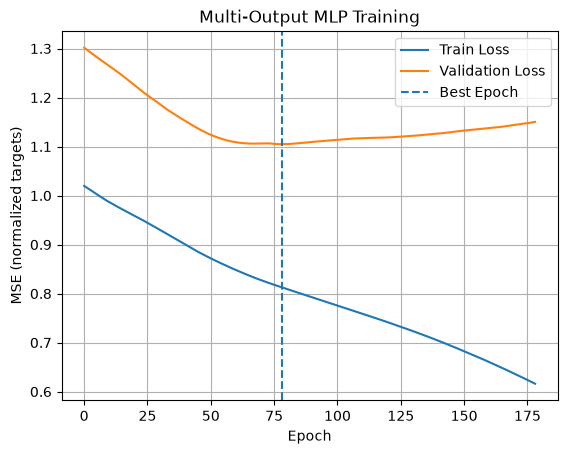

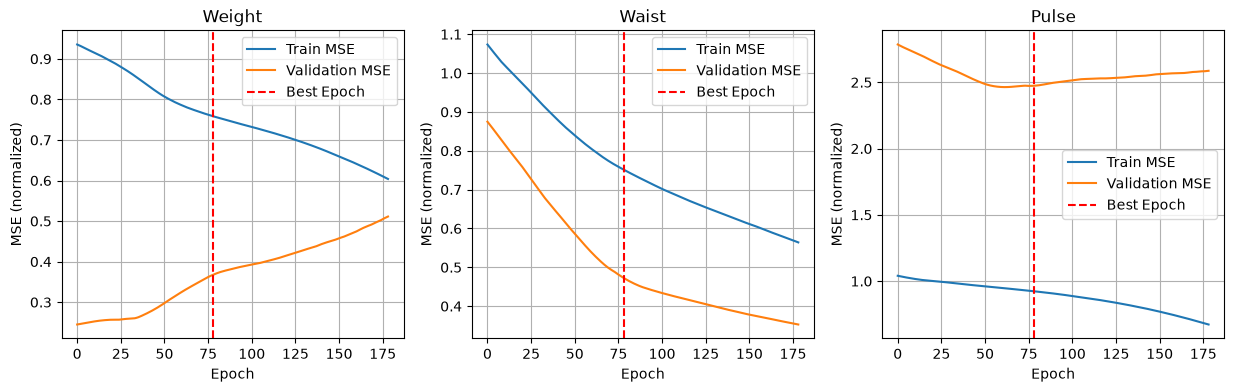

In [11]:

# 9. График
plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")
plt.axvline(best_epoch - 1, linestyle="--", label="Best Epoch")

plt.xlabel("Epoch")
plt.ylabel("MSE (normalized targets)")
plt.title("Multi-Output MLP Training")
plt.legend()
plt.grid()
import numpy as np
import matplotlib.pyplot as plt

train_mse_history = np.array(train_mse_history)
val_mse_history = np.array(val_mse_history)

names = ["Weight", "Waist", "Pulse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(
        train_mse_history[:, i],
        label="Train MSE"
    )

    axes[i].plot(
        val_mse_history[:, i],
        label="Validation MSE"
    )

    axes[i].axvline(
        best_epoch - 1,
        color="red",
        linestyle="--",
        label="Best Epoch"
    )

    axes[i].set_title(names[i])
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (normalized)")
    axes[i].grid(True)
    axes[i].legend()


### Завершаем построение графиков

Выводим подготовленные кривые. Сопоставляем форму графиков с результатами Early Stopping и различием между ошибками трёх выходов.

In [12]:

plt.tight_layout()
plt.show()
plt.show()

<Figure size 640x480 with 0 Axes>

### Дополнительный эксперимент: усиление веса ошибки Weight
Гипотеза — увеличение первого коэффициента до 2 изменит компромисс между целями. Сохраняем разбиение, seed, архитектуру, Adam и patience. Сравниваем раздельные validation MSE, поскольку суммарные взвешенные loss между этими вариантами имеют разный масштаб. Дополнительный test для настройки не используется.

Сравнение: веса / лучшая эпоха / validation MSE трёх масштабированных целей
([1.0, 1.0, 1.0], 79, array([0.36792308, 0.47267574, 2.4740381 ], dtype=float32))
([2.0, 1.0, 1.0], 106, array([0.41764024, 0.42889792, 2.4032009 ], dtype=float32))


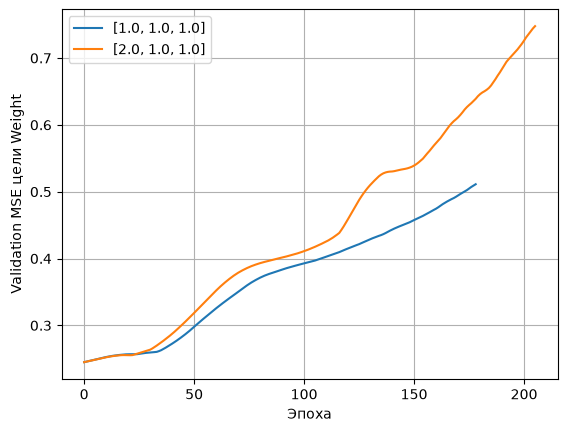

In [13]:
# Новый контролируемый опыт: меняем только веса целей.
# Данные и нормализация берутся из этапов выше. Повторяем исходную архитектуру.
weighted_results = []
for loss_weights in ([1.0, 1.0, 1.0], [2.0, 1.0, 1.0]):
    torch.manual_seed(42)
    weighted_model = nn.Sequential(nn.Linear(3, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 3))
    weighted_optimizer = torch.optim.Adam(weighted_model.parameters(), lr=0.001, weight_decay=0.01)
    weight_tensor = torch.tensor(loss_weights)
    weighted_best = float('inf')
    weighted_stale = 0
    weighted_history = []
    for weighted_epoch in range(1000):
        weighted_optimizer.zero_grad()
        weighted_loss = (((weighted_model(X_train) - y_train) ** 2) * weight_tensor).mean()
        weighted_loss.backward()
        weighted_optimizer.step()
        with torch.no_grad():
            weighted_val = (((weighted_model(X_val) - y_val) ** 2) * weight_tensor).mean().item()
            weighted_per_target = ((weighted_model(X_val) - y_val) ** 2).mean(dim=0).numpy()
        weighted_history.append(weighted_per_target.copy())
        if weighted_val < weighted_best:
            weighted_best = weighted_val
            weighted_best_epoch = weighted_epoch + 1
            weighted_state = copy.deepcopy(weighted_model.state_dict())
            weighted_stale = 0
        else:
            weighted_stale += 1
        if weighted_stale >= 100:
            break
    weighted_model.load_state_dict(weighted_state)
    with torch.no_grad():
        weighted_mse = ((weighted_model(X_val) - y_val) ** 2).mean(dim=0).numpy()
    weighted_results.append((loss_weights, weighted_best_epoch, weighted_mse.copy()))
    plt.plot(np.asarray(weighted_history)[:, 0], label=str(loss_weights))
print('Сравнение: веса / лучшая эпоха / validation MSE трёх масштабированных целей')
for row in weighted_results:
    print(row)
plt.xlabel('Эпоха'); plt.ylabel('Validation MSE цели Weight'); plt.legend(); plt.grid(); plt.show()


### Результаты сравнения с весами
| Веса целей | Лучшая эпоха | Val MSE Weight | Val MSE Waist | Val MSE Pulse |
|---|---:|---:|---:|---:|
| [1, 1, 1] | 79 | 0.367923 | 0.472676 | 2.474038 |
| [2, 1, 1] | 106 | 0.417640 | 0.428898 | 2.403201 |

Все MSE в этой таблице вычислены для масштабированных целей. Усиление веса Weight в этом опыте ухудшило её validation MSE. Оптимизатор минимизирует взвешенную ошибку на train, что не гарантирует улучшения выбранной цели на validation.

## Выводы

Общий loss и MSE отдельных выходов показывают разные стороны качества. Увеличение веса Weight меняет баланс ошибок, поэтому сравниваем все три выхода. Из-за малого размера Linnerud результат сильно зависит от разбиения.


## Полный код


X: (20, 3)
y: (20, 3)
Epoch  20 | Train: 0.96110 | Val: 1.22905
Epoch  40 | Train: 0.90273 | Val: 1.15507
Epoch  60 | Train: 0.85013 | Val: 1.10962
Epoch  80 | Train: 0.81111 | Val: 1.10492
Epoch 100 | Train: 0.77727 | Val: 1.11352
Epoch 120 | Train: 0.74310 | Val: 1.11846
Epoch 140 | Train: 0.70554 | Val: 1.12616
Epoch 160 | Train: 0.66243 | Val: 1.13710
Early Stopping!

Лучшая эпоха: 79
Лучший Validation MSE: 1.1048791408538818

TEST RESULTS
Weight: MSE = 159.9478
Waist: MSE = 2.7872
Pulse: MSE = 24.4133

Первое предсказание:
Предсказано: [169.48  35.07  55.88]
Правильный ответ: [157.  32.  52.]


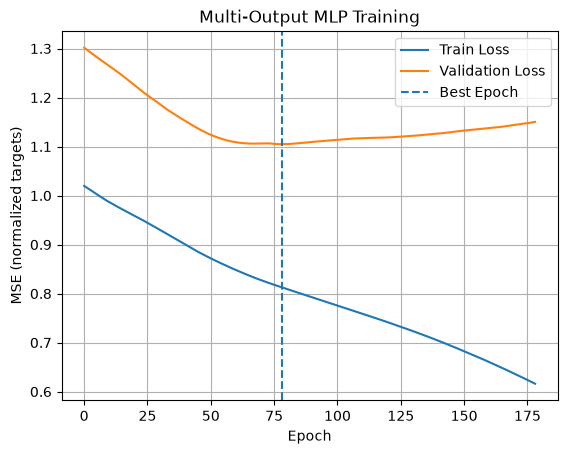

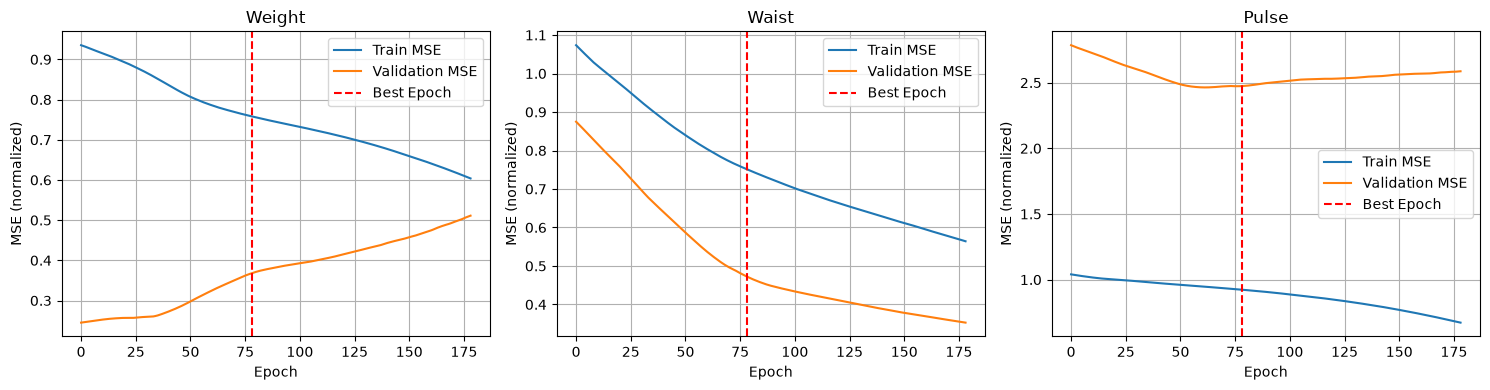

Сравнение: веса / лучшая эпоха / validation MSE трёх масштабированных целей
([1.0, 1.0, 1.0], 79, array([0.36792308, 0.47267574, 2.4740381 ], dtype=float32))
([2.0, 1.0, 1.0], 106, array([0.41764024, 0.42889792, 2.4032009 ], dtype=float32))


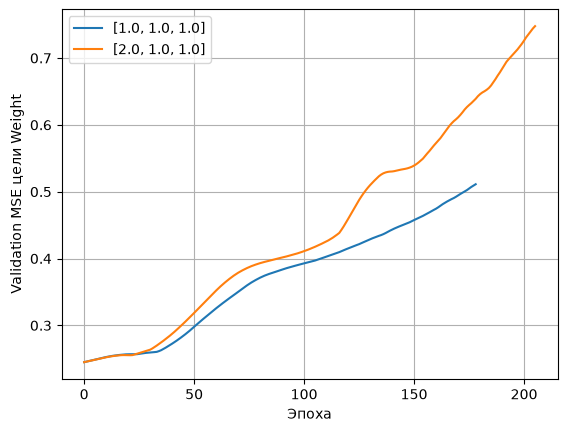

In [14]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

torch.manual_seed(42)
np.random.seed(42)

# 1. Готовый датасет
data = load_linnerud()

X = data.data.astype(np.float32)
y = data.target.astype(np.float32)

print("X:", X.shape)
print("y:", y.shape)

# 2. Разделение данных
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# 3. Нормализация по обучающим данным
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train)
y_val = scaler_y.transform(y_val)
y_test = scaler_y.transform(y_test)

# 4. Преобразование в тензоры
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

# 5. Многовыходная MLP
model = nn.Sequential(
    nn.Linear(3, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

patience = 30
loss_fn = nn.MSELoss()

train_history = []
val_history = []

best_val_loss = float("inf")
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())

patience = 100
epochs_without_improvement = 0

# 6. Обучение
train_mse_history = []
val_mse_history = []

# Веса ошибок трёх выходов
weights = torch.tensor([1.0, 1.0, 1.0])

for epoch in range(1000):
    model.train()

    optimizer.zero_grad()

    predictions = model(X_train)

    # Квадраты ошибок каждого выхода
    errors = (predictions - y_train) ** 2

    # Взвешенная ошибка
    train_loss = (errors * weights).mean()

    train_loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)

        val_errors = (val_predictions - y_val) ** 2
        val_loss = (val_errors * weights).mean()

    with torch.no_grad():
        train_mse = ((model(X_train) - y_train) ** 2).mean(dim=0)
        val_mse = ((model(X_val) - y_val) ** 2).mean(dim=0)

        train_mse_history.append(train_mse.cpu().numpy().copy())
        val_mse_history.append(val_mse.cpu().numpy().copy())

    train_history.append(train_loss.item())
    val_history.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train: {train_loss.item():.5f} | "
            f"Val: {val_loss.item():.5f}"
        )

    if epochs_without_improvement >= patience:
        print("Early Stopping!")
        break

# 7. Восстановление лучших весов
model.load_state_dict(best_weights)
model.eval()

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation MSE:", best_val_loss)

# 8. Проверка на тестовых данных
with torch.no_grad():
    test_predictions = model(X_test).numpy()

# Возвращаем исходные единицы измерения
test_predictions = scaler_y.inverse_transform(test_predictions)
y_test_original = scaler_y.inverse_transform(y_test)

print("\nTEST RESULTS")

for i, name in enumerate(data.target_names):
    mse = mean_squared_error(
        y_test_original[:, i],
        test_predictions[:, i]
    )
    print(f"{name}: MSE = {mse:.4f}")

print("\nПервое предсказание:")
print("Предсказано:", test_predictions[0].round(2))
print("Правильный ответ:", y_test_original[0].round(2))

# 9. График
plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")
plt.axvline(best_epoch - 1, linestyle="--", label="Best Epoch")

plt.xlabel("Epoch")
plt.ylabel("MSE (normalized targets)")
plt.title("Multi-Output MLP Training")
plt.legend()
plt.grid()
import numpy as np
import matplotlib.pyplot as plt

train_mse_history = np.array(train_mse_history)
val_mse_history = np.array(val_mse_history)

names = ["Weight", "Waist", "Pulse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    axes[i].plot(
        train_mse_history[:, i],
        label="Train MSE"
    )

    axes[i].plot(
        val_mse_history[:, i],
        label="Validation MSE"
    )

    axes[i].axvline(
        best_epoch - 1,
        color="red",
        linestyle="--",
        label="Best Epoch"
    )

    axes[i].set_title(names[i])
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (normalized)")
    axes[i].grid(True)
    axes[i].legend()

plt.tight_layout()
plt.show()
plt.show()

# Новый контролируемый опыт: меняем только веса целей.
# Данные и нормализация берутся из этапов выше. Повторяем исходную архитектуру.
weighted_results = []
for loss_weights in ([1.0, 1.0, 1.0], [2.0, 1.0, 1.0]):
    torch.manual_seed(42)
    weighted_model = nn.Sequential(nn.Linear(3, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 3))
    weighted_optimizer = torch.optim.Adam(weighted_model.parameters(), lr=0.001, weight_decay=0.01)
    weight_tensor = torch.tensor(loss_weights)
    weighted_best = float('inf')
    weighted_stale = 0
    weighted_history = []
    for weighted_epoch in range(1000):
        weighted_optimizer.zero_grad()
        weighted_loss = (((weighted_model(X_train) - y_train) ** 2) * weight_tensor).mean()
        weighted_loss.backward()
        weighted_optimizer.step()
        with torch.no_grad():
            weighted_val = (((weighted_model(X_val) - y_val) ** 2) * weight_tensor).mean().item()
            weighted_per_target = ((weighted_model(X_val) - y_val) ** 2).mean(dim=0).numpy()
        weighted_history.append(weighted_per_target.copy())
        if weighted_val < weighted_best:
            weighted_best = weighted_val
            weighted_best_epoch = weighted_epoch + 1
            weighted_state = copy.deepcopy(weighted_model.state_dict())
            weighted_stale = 0
        else:
            weighted_stale += 1
        if weighted_stale >= 100:
            break
    weighted_model.load_state_dict(weighted_state)
    with torch.no_grad():
        weighted_mse = ((weighted_model(X_val) - y_val) ** 2).mean(dim=0).numpy()
    weighted_results.append((loss_weights, weighted_best_epoch, weighted_mse.copy()))
    plt.plot(np.asarray(weighted_history)[:, 0], label=str(loss_weights))
print('Сравнение: веса / лучшая эпоха / validation MSE трёх масштабированных целей')
for row in weighted_results:
    print(row)
plt.xlabel('Эпоха'); plt.ylabel('Validation MSE цели Weight'); plt.legend(); plt.grid(); plt.show()
